## Optimal grid tariff for peak shaving

In [14]:
# Import libraries
from pathlib import Path
import cvxpy as cp
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import json

from demand_reduction_utils import *
from demand_xgboost import load_iflex_aggregate, tuning, best_params
from demand_xgboost_scenarios import make_calibration_residuals, make_residual_block_scenarios

### Load parameters

In [15]:
# config parameters
with open("config.json") as config_file:
    config = json.load(config_file)

PATHS = config["PATHS"]
MERGED_DATA_PATH = Path(PATHS["MERGED_DATA_PATH"])
RAW_DATA_PATH =  Path(PATHS["RAW_DATA_PATH"])
TUNING_RESULTS_PATH = Path(PATHS["TUNING_RESULTS_PATH"])
VALIDATION_RESULTS_PATH = Path(PATHS["VALIDATION_RESULTS_PATH"])
RAW_XGB_RESULTS_PATH = Path(PATHS["RAW_XGB_RESULTS_PATH"])
FINAL_RESULTS_PATH = Path(PATHS["FINAL_RESULTS_PATH"])

aggregation_columns = config["aggregation_columns"]
candidate_feature_sets = config["candidate_feature_sets"]
candidate_xg_boost_params = config["candidate_xg_boost_params"]
tuning_metric = config["tuning_metric"]
grid_charge = config["grid_charge"]
eur_to_nok = config["eur_to_nok"]
E = config["price_elasticity"]
R = 12
S_bar = 1

### Load data

In [16]:
df_agg = load_iflex_aggregate(E, grid_charge, eur_to_nok, MERGED_DATA_PATH, RAW_DATA_PATH, aggregation_columns)
communities = sorted(df_agg["Group"].dropna().unique())
all_dates = sorted(df_agg["Date"].drop_duplicates())

print(f"Date range: {all_dates[0].date()} to {all_dates[-1].date()} ({len(all_dates)} experiment dates)")
print(f"Communities: {len(communities)}")
df_agg.head()


# Basic data integrity checks
assert not df_agg.duplicated(subset=["Group", "time"]).any(), "Duplicate community-hour rows detected"
assert df_agg["demand"].notna().all(), "Missing aggregated demand values detected"
assert df_agg["temperature_24h_avg"].notna().all(), "Missing 24-hour average temperature feature values detected"

summary = pd.DataFrame(
    {
        "metric": ["community_hour_rows", "communities", "experiment_dates", "min_demand", "max_demand"],
        "value": [
            len(df_agg),
            df_agg["Group"].nunique(),
            df_agg["Date"].nunique(),
            df_agg["demand"].min(),
            df_agg["demand"].max(),
        ],
    }
)
summary

Loaded 44,176 community-hour rows from iFlex_merged_data.csv in 10.7s
Date range: 2020-12-01 to 2021-03-26 (116 experiment dates)
Communities: 16


,metric,value
0,community_hour_rows,44176.000000
1,communities,16.000000
2,experiment_dates,116.000000
3,min_demand,1.171963
4,max_demand,4.116354


### Results + plots

In [17]:
# Set plot theme
sns.set_theme(
    style="ticks",
    font="serif",
    rc={
        "font.serif": ["Times New Roman", "Times", "STIXGeneral"],
        "mathtext.fontset": "stix",
        "axes.grid": False,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "axes.edgecolor": "black",
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": "black",
        "text.color": "black",
        "xtick.color": "black",
        "ytick.color": "black",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.width": 1,
        "ytick.major.width": 1,
        "xtick.minor.width": 1,
        "ytick.minor.width": 1,
        "legend.frameon": False,
    },
)

In [18]:
# Define number of dates, number of scenarios, and CVaR beta values with which to test algos
N_eval_dates = 10
N_scenarios = 7
eval_dates = all_dates[-N_eval_dates-1:-1]
tuning_dates = all_dates[-2*N_eval_dates-N_scenarios-1:-N_eval_dates-N_scenarios-1]

In [19]:
# Recompute these outputs so cached files cannot preserve stale training windows
# or duplicated rows from earlier notebook runs.
if TUNING_RESULTS_PATH.exists():
    tuning_results = pd.read_csv(TUNING_RESULTS_PATH)
else:
    tuning_results = tuning(candidate_feature_sets, 
                candidate_xg_boost_params,
                df_agg, 
                tuning_dates, 
                tuning_metric)
    tuning_results.to_csv(TUNING_RESULTS_PATH, index=False)

best_feature_name, best_feature_cols, best_model_params = best_params(candidate_feature_sets, tuning_results)
print(f"Best XGBoost parameters: {best_feature_name}, {best_model_params}")

Best XGBoost parameters: time_weather_price, {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0.0, 'reg_lambda': 1.0, 'subsample': 0.9}


#### Deterministic case study

In [20]:
# deterministic case: simulate algorithms on actual demand from evaluation dates
# shift = 0
fill = False
beta_options = [0]
pi_step = 0.01
metrics_deterministic = pd.DataFrame()

df_deterministic = df_agg.copy()
df_deterministic["Date"] = pd.to_datetime(df_deterministic["Date"]).dt.normalize()
df_deterministic["time"] = pd.to_datetime(df_deterministic["time"])
df_deterministic["scenario_demand"] = df_deterministic["demand"]
df_deterministic["scenario_id"] = 0

for date in eval_dates:
    if (date >= all_dates[N_scenarios]) & (date < all_dates[-1]):
        print(f"Optimizing for date: {date}")
        final_test_date = pd.Timestamp(date).normalize()
        
        block_scenarios = df_deterministic.loc[df_deterministic["Date"] == final_test_date]

        for beta in beta_options:
            print(f"Running CVaR beta={beta:.3f} for {final_test_date.date()}")
            deterministic_results = run_algos(df_agg, communities, block_scenarios, final_test_date, R, E, fill, beta, pi_step)

            df_metrics_deterministic_grouped = test_models(deterministic_results, df_agg, final_test_date, E, fill)
            df_metrics_deterministic_grouped["Date"] = final_test_date
            df_metrics_deterministic_grouped["beta"] = beta
            df_metrics_deterministic_grouped["pi_step"] = pi_step
            metrics_deterministic = pd.concat([metrics_deterministic, df_metrics_deterministic_grouped], ignore_index=True)

Optimizing for date: 2021-03-16 00:00:00
Running CVaR beta=0.000 for 2021-03-16
Optimizing for date: 2021-03-17 00:00:00
Running CVaR beta=0.000 for 2021-03-17
Optimizing for date: 2021-03-18 00:00:00
Running CVaR beta=0.000 for 2021-03-18
Optimizing for date: 2021-03-19 00:00:00
Running CVaR beta=0.000 for 2021-03-19
Optimizing for date: 2021-03-20 00:00:00
Running CVaR beta=0.000 for 2021-03-20
Optimizing for date: 2021-03-21 00:00:00
Running CVaR beta=0.000 for 2021-03-21
Optimizing for date: 2021-03-22 00:00:00
Running CVaR beta=0.000 for 2021-03-22
Optimizing for date: 2021-03-23 00:00:00
Running CVaR beta=0.000 for 2021-03-23
Optimizing for date: 2021-03-24 00:00:00
Running CVaR beta=0.000 for 2021-03-24
Optimizing for date: 2021-03-25 00:00:00
Running CVaR beta=0.000 for 2021-03-25


In [21]:
# Simulate benchmarks on evaluation dates
metrics_benchmark = pd.DataFrame()
for date in eval_dates:
    date = pd.Timestamp(date).normalize()
    print(f"Running benchmarks for date: {date.date()}")
    benchmark_results = run_benchmarks(df_agg, communities, date, R, E, tariff=0.5, start_hour=8, end_hour=20, fill=fill, beta=beta, pi_step=pi_step)

    df_metrics_grouped = test_models(benchmark_results, df_agg, date, E, fill)
    df_metrics_grouped["Date"] = date
    metrics_benchmark = pd.concat([metrics_benchmark, df_metrics_grouped], ignore_index=True)

Running benchmarks for date: 2021-03-16
Running benchmarks for date: 2021-03-17
Running benchmarks for date: 2021-03-18
Running benchmarks for date: 2021-03-19
Running benchmarks for date: 2021-03-20
Running benchmarks for date: 2021-03-21
Running benchmarks for date: 2021-03-22
Running benchmarks for date: 2021-03-23
Running benchmarks for date: 2021-03-24
Running benchmarks for date: 2021-03-25


In [22]:
# compute performance metrics (regret) and aggregate for plots
# compare peak shaving algorithms with perfect foresight
metrics_deterministic = metrics_deterministic.loc[metrics_deterministic["Method"].isin(["greedy", "relaxed_overshoot"])]
metrics_comparison_deterministic = metrics_deterministic.merge(metrics_benchmark.loc[metrics_benchmark["Method"] == "foresight_greedy"], on=["Group", "Date"], how="left", suffixes=("_cvar", "_benchmark"))
metrics_comparison_deterministic["regret"] = metrics_comparison_deterministic[f"peak_demand_cvar"] - metrics_comparison_deterministic["peak_demand_benchmark"]
metrics_comparison_deterministic[f"R_violation"] = np.maximum(metrics_comparison_deterministic[f"R_sum_cvar"] - R,0)
# peak demand before shaving
df_agg_peak_demand = df_agg.groupby(["Group", "Date"])["demand"].max().reset_index().rename(columns={"demand": "peak_demand_original"})
metrics_comparison_deterministic = metrics_comparison_deterministic.merge(df_agg_peak_demand, on=["Group", "Date"], how="left")
# aggregate peak demand and revenue for pareto figure
metrics_deterministic_agg = metrics_deterministic.groupby(["Date", "Method", "beta", "pi_step"]).agg({"peak_demand": "mean", "R_sum": "mean"}).reset_index()
metrics_benchmark_agg = metrics_benchmark.groupby(["Date", "Method"]).agg({"peak_demand": "mean", "R_sum": "mean"}).reset_index()

In [23]:
print(metrics_deterministic_agg.groupby("Method").agg({"peak_demand": ["min", "max"], "R_sum": ["min", "max"]}))
print(metrics_benchmark_agg.groupby("Method").agg({"peak_demand": ["min", "max"], "R_sum": ["min", "max"]}))

                  peak_demand                R_sum           
                          min       max        min        max
Method                                                       
greedy               2.213787  2.608409  12.008084  12.013808
relaxed_overshoot    2.212177  2.606797  12.262401  12.387959
                 peak_demand                R_sum           
                         min       max        min        max
Method                                                      
foresight_greedy    2.213787  2.608409  12.008084  12.013808
tou                 2.353196  2.736328  12.735561  15.275417


In [24]:
palette_cvar = {
    'relaxed_overshoot': 'darkolivegreen',
    'greedy': 'olive'
}

palette_benchmark = {
    'foresight_greedy': 'firebrick',
    'tou': 'lightcoral'
}

# Legend labels for the methods
method_labels = {
    "greedy": "Numerical",
    "relaxed_overshoot": "Convex Relaxation",
    "foresight_greedy": "Perfect Foresight",
    "tou": "TOU",
}

Regret Distribution Across Communities and Dates, Beta = 0.000


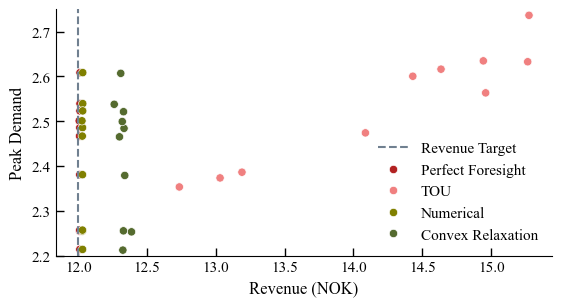

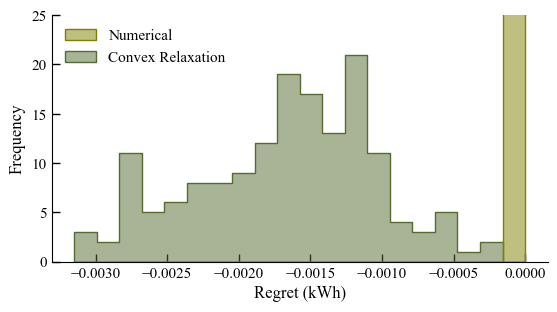

Regret vs. Original Peak Demand, Beta = 0.000


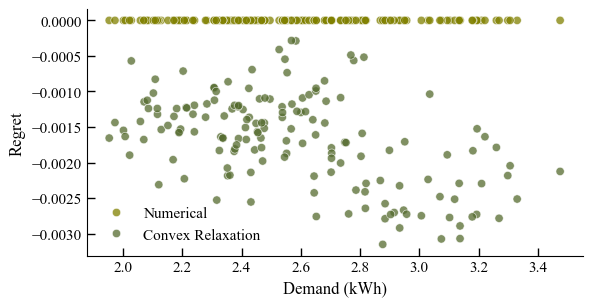

Revenue Distribution Across Communities and Dates, Beta = 0.000


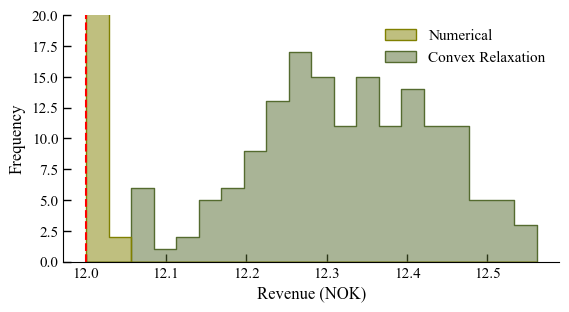

In [25]:
# plot deterministic results
pareto_figure(metrics_deterministic_agg, metrics_benchmark_agg, R, palette_cvar, palette_benchmark, method_labels, ymin=2.2,ymax=2.75)

beta_options = [0]
for beta in beta_options:
    metrics_beta = metrics_comparison_deterministic.loc[metrics_comparison_deterministic["beta"] == beta]
    
    # regret histogram
    plot_regret_histogram(metrics_beta, beta, palette_cvar, method_labels, ymax=25)

    # regret vs. original peak demand
    plot_regret_vs_original_peak(metrics_beta, beta, palette_cvar, method_labels)

    # daily revenue histogram
    plot_revenue_histogram(metrics_beta, beta, R, palette_cvar, method_labels, height=20)

#### Scenario-based uncertainty case study

In [ ]:
# Simulate algorithms on evaluation dates
beta_options = [i / N_scenarios for i in range(int(N_scenarios/2), N_scenarios)]
metrics_cvar = pd.DataFrame()

if "xgb_results" not in globals():
    if RAW_XGB_RESULTS_PATH.exists():
        xgb_results = pd.read_csv(RAW_XGB_RESULTS_PATH)
    else:
        xgb_results = run_xgboost(df_agg, all_dates[-N_eval_dates-N_scenarios-1:-1], best_feature_cols, best_model_params, RAW_XGB_RESULTS_PATH)

xgb_results["Date"] = pd.to_datetime(xgb_results["Date"]).dt.normalize()
xgb_results["time"] = pd.to_datetime(xgb_results["time"])

for date in eval_dates:
    if (date >= all_dates[N_scenarios]) & (date < all_dates[-1]):
        print(f"Optimizing for date: {date}")
        final_test_date = pd.Timestamp(date).normalize()
        idx = all_dates.index(date)
        validation_dates = [pd.Timestamp(d).normalize() for d in all_dates[idx-N_scenarios:idx]]

        final_forecast = xgb_results[xgb_results["Date"] == final_test_date]
        validation_kernel_results = xgb_results[xgb_results["Date"].isin(validation_dates)]
        calibration_residuals = make_calibration_residuals(validation_kernel_results)

        block_scenarios = make_residual_block_scenarios(final_forecast, calibration_residuals)
        block_scenarios = block_scenarios.merge(
            df_agg[["Group", "time", "Energy_Price_NOK_kWh"]], on=["Group", "time"], how="left"
        )

        for beta in beta_options:
            print(f"Running CVaR beta={beta:.3f} for {final_test_date.date()}")
            cvar_results = run_algos(df_agg, communities, block_scenarios, final_test_date, R, E, fill, beta, 0.01)

            df_metrics_grouped = test_models(cvar_results, df_agg, final_test_date, E, fill)
            df_metrics_grouped["Date"] = final_test_date
            df_metrics_grouped["beta"] = beta
            metrics_cvar = pd.concat([metrics_cvar, df_metrics_grouped], ignore_index=True)


Optimizing for date: 2021-03-16 00:00:00
Running CVaR beta=0.429 for 2021-03-16
Running CVaR beta=0.571 for 2021-03-16
Running CVaR beta=0.714 for 2021-03-16
Running CVaR beta=0.857 for 2021-03-16
Optimizing for date: 2021-03-17 00:00:00
Running CVaR beta=0.429 for 2021-03-17
Running CVaR beta=0.571 for 2021-03-17
Running CVaR beta=0.714 for 2021-03-17
Running CVaR beta=0.857 for 2021-03-17
Optimizing for date: 2021-03-18 00:00:00
Running CVaR beta=0.429 for 2021-03-18
Running CVaR beta=0.571 for 2021-03-18
Running CVaR beta=0.714 for 2021-03-18
Running CVaR beta=0.857 for 2021-03-18
Optimizing for date: 2021-03-19 00:00:00
Running CVaR beta=0.429 for 2021-03-19
Running CVaR beta=0.571 for 2021-03-19
Running CVaR beta=0.714 for 2021-03-19
Running CVaR beta=0.857 for 2021-03-19
Optimizing for date: 2021-03-20 00:00:00
Running CVaR beta=0.429 for 2021-03-20
Running CVaR beta=0.571 for 2021-03-20
Running CVaR beta=0.714 for 2021-03-20
Running CVaR beta=0.857 for 2021-03-20
Optimizing for 

In [ ]:
# compute performance metrics (regret) and aggregate for plots

# compare peak shaving algorithms with perfect foresight
metrics_comparison = metrics_cvar.merge(metrics_benchmark.loc[metrics_benchmark["Method"] == "foresight_greedy"], on=["Group", "Date"], how="left", suffixes=("_cvar", "_benchmark"))
metrics_comparison["regret"] = metrics_comparison[f"peak_demand_cvar"] - metrics_comparison["peak_demand_benchmark"]
metrics_comparison[f"R_violation"] = np.maximum(metrics_comparison[f"R_sum_cvar"] - R,0)
# peak demand before shaving
df_agg_peak_demand = df_agg.groupby(["Group", "Date"])["demand"].max().reset_index().rename(columns={"demand": "peak_demand_original"})
metrics_comparison = metrics_comparison.merge(df_agg_peak_demand, on=["Group", "Date"], how="left")
# aggregate peak demand and revenue for pareto figure
metrics_cvar_agg = metrics_cvar.groupby(["Date", "Method", "beta"]).agg({"peak_demand": "mean", "R_sum": "mean"}).reset_index()

In [ ]:
print(metrics_cvar_agg.groupby("Method").agg({"peak_demand": ["min", "max", "mean"], "R_sum": ["min", "max", "mean"]}))
print(metrics_benchmark_agg.groupby("Method").agg({"peak_demand": ["min", "max"], "R_sum": ["min", "max"]}))

                  peak_demand                          R_sum             \
                          min       max      mean        min        max   
Method                                                                    
greedy               2.276600  2.707741  2.509077  11.273848  12.266215   
relaxed_overshoot    2.277143  2.703557  2.504622  11.430882  12.707183   

                              
                        mean  
Method                        
greedy             11.788986  
relaxed_overshoot  12.144624  
                 peak_demand                R_sum           
                         min       max        min        max
Method                                                      
foresight_greedy    2.213787  2.608409  12.008084  12.013808
tou                 2.353196  2.736328  12.735561  15.275417


In [ ]:
metrics_cvar_agg.loc[metrics_cvar_agg["Date"] == "2021-03-25"]

,Date,Method,beta,peak_demand,R_sum
72,2021-03-25,greedy,0.428571,2.322485,11.565020
73,2021-03-25,greedy,0.571429,2.329538,11.540552
74,2021-03-25,greedy,0.714286,2.341685,11.507117
75,2021-03-25,greedy,0.857143,2.349773,11.514705
76,2021-03-25,relaxed_overshoot,0.428571,2.318757,11.960234
77,2021-03-25,relaxed_overshoot,0.571429,2.327456,11.916154
78,2021-03-25,relaxed_overshoot,0.714286,2.337458,11.884221
79,2021-03-25,relaxed_overshoot,0.857143,2.348732,11.836049


Regret Distribution Across Communities and Dates, Beta = 0.429


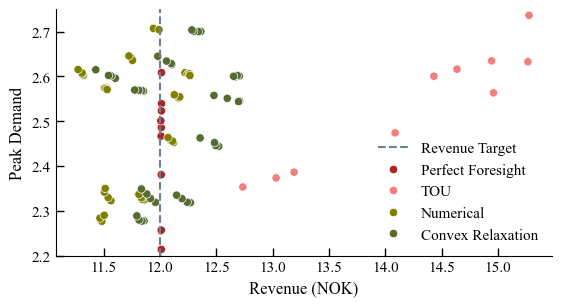

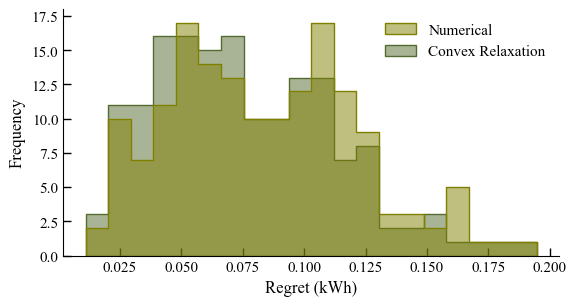

Regret vs. Original Peak Demand, Beta = 0.429


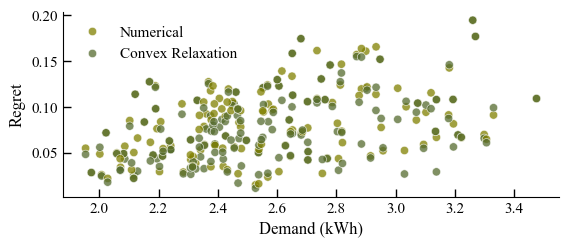

Revenue Distribution Across Communities and Dates, Beta = 0.429


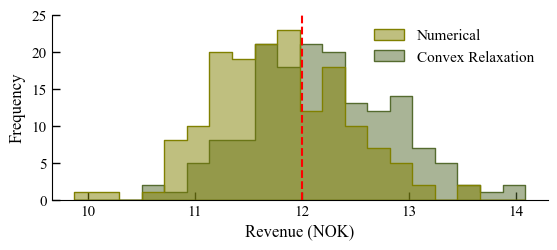

Regret Distribution Across Communities and Dates, Beta = 0.571


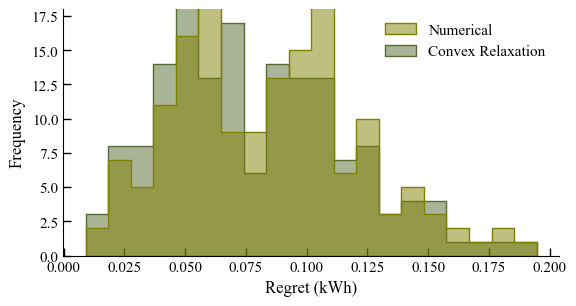

Regret vs. Original Peak Demand, Beta = 0.571


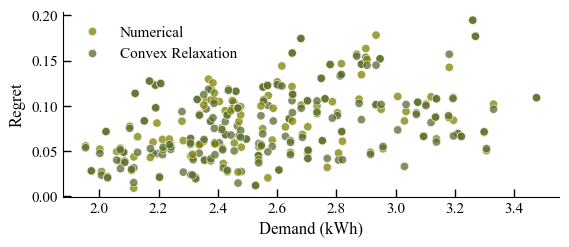

Revenue Distribution Across Communities and Dates, Beta = 0.571


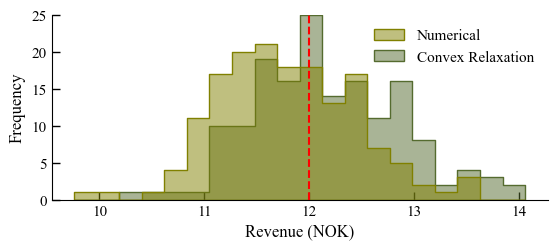

Regret Distribution Across Communities and Dates, Beta = 0.714


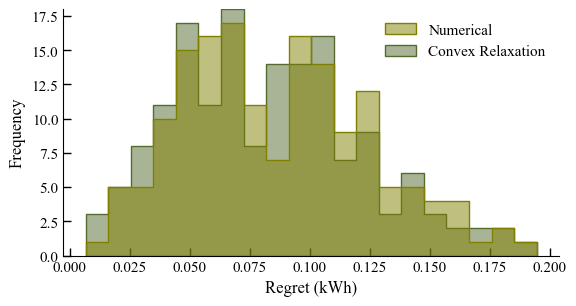

Regret vs. Original Peak Demand, Beta = 0.714


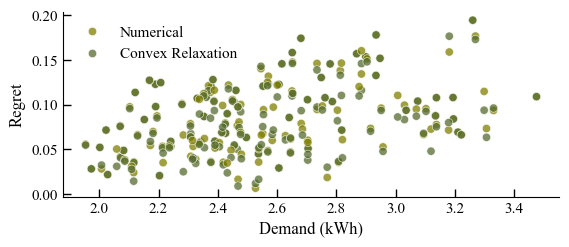

Revenue Distribution Across Communities and Dates, Beta = 0.714


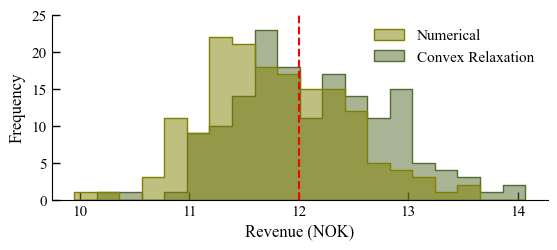

Regret Distribution Across Communities and Dates, Beta = 0.857


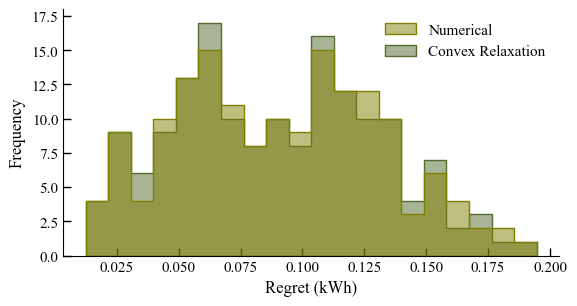

Regret vs. Original Peak Demand, Beta = 0.857


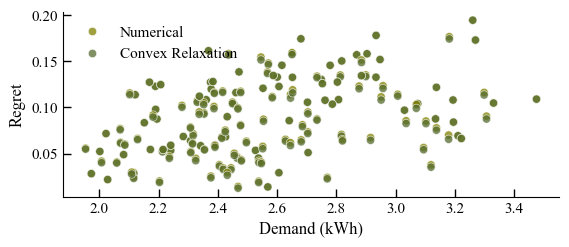

Revenue Distribution Across Communities and Dates, Beta = 0.857


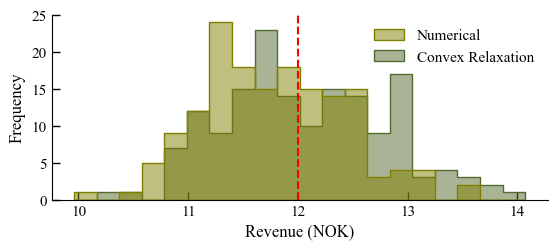

In [ ]:
# plot results
pareto_figure(metrics_cvar_agg, metrics_benchmark_agg, R, palette_cvar, palette_benchmark, method_labels, ymin=2.2,ymax=2.75)

beta_options = [i / N_scenarios for i in range(int(N_scenarios/2), N_scenarios)]
for beta in beta_options:
    metrics_beta = metrics_comparison.loc[metrics_comparison["beta"] == beta]
    
    # regret histogram
    plot_regret_histogram(metrics_beta, beta, palette_cvar, method_labels, ymax=18)

    # regret vs. original peak demand
    plot_regret_vs_original_peak(metrics_beta, beta, palette_cvar, method_labels)

    # daily revenue histogram
    plot_revenue_histogram(metrics_beta, beta, R, palette_cvar, method_labels, height=25)

In [97]:
# simulate effect of tariff for one date, community, and beta value
beta = 4/7
date = all_dates[-2]

final_test_date = pd.Timestamp(date).normalize()
idx = all_dates.index(date)
validation_dates = [pd.Timestamp(d).normalize() for d in all_dates[idx-7:idx]]

final_forecast = xgb_results[xgb_results["Date"] == final_test_date]
validation_kernel_results = xgb_results[xgb_results["Date"].isin(validation_dates)]
calibration_residuals = make_calibration_residuals(validation_kernel_results)

block_scenarios = make_residual_block_scenarios(final_forecast, calibration_residuals)
block_scenarios = block_scenarios.merge(
    df_agg[["Group", "time", "Energy_Price_NOK_kWh"]], on=["Group", "time"], how="left"
)

example_cvar_results = run_algos(df_agg, communities, block_scenarios, final_test_date, R, E, fill, beta, 0.01)

Peak Shaving Simulation - Community Ber_1 on 2021-03-25


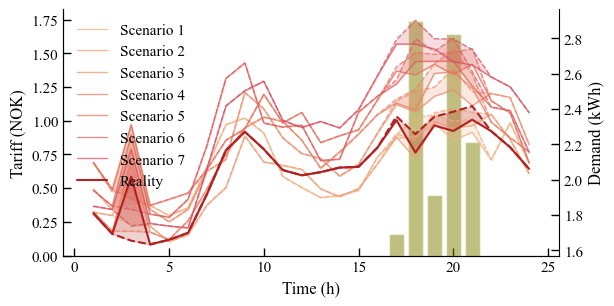

Peak Shaving Simulation - Community Ber_1 on 2021-03-25


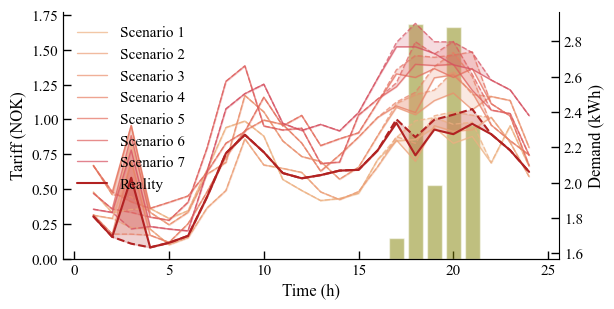

In [98]:
results=example_cvar_results.copy()
data=df_agg.copy()
scenarios=block_scenarios.copy()
for community in ["Ber_1"]: #results["Group"].drop_duplicates():
    comm_results = results.loc[results['Group'] == community]
    T, N, _, D_scenarios, D, l = prep_params(data, scenarios, community, date)

    peaks = np.max(D_scenarios, axis=0) 
    sort_indices = np.argsort(peaks)
    D_scenarios = D_scenarios[:, sort_indices]

    time = comm_results['Hour'].unique()
    pi_greedy = comm_results.loc[comm_results["Method"] == "greedy", "pi"].to_numpy()
    
    pi_relaxed_overshoot = comm_results.loc[comm_results["Method"] == "relaxed_overshoot", "pi"].to_numpy()

    plot_simulation(time, pi_greedy, N, D_scenarios, D,E, l, fill, date, community)
    plot_simulation(time, pi_relaxed_overshoot, N, D_scenarios, D, E, l, fill, date, community)